Caso 1: Neutrinos sem massa (3 famílias)

Caso 2: Neutrinos com massas diferentes


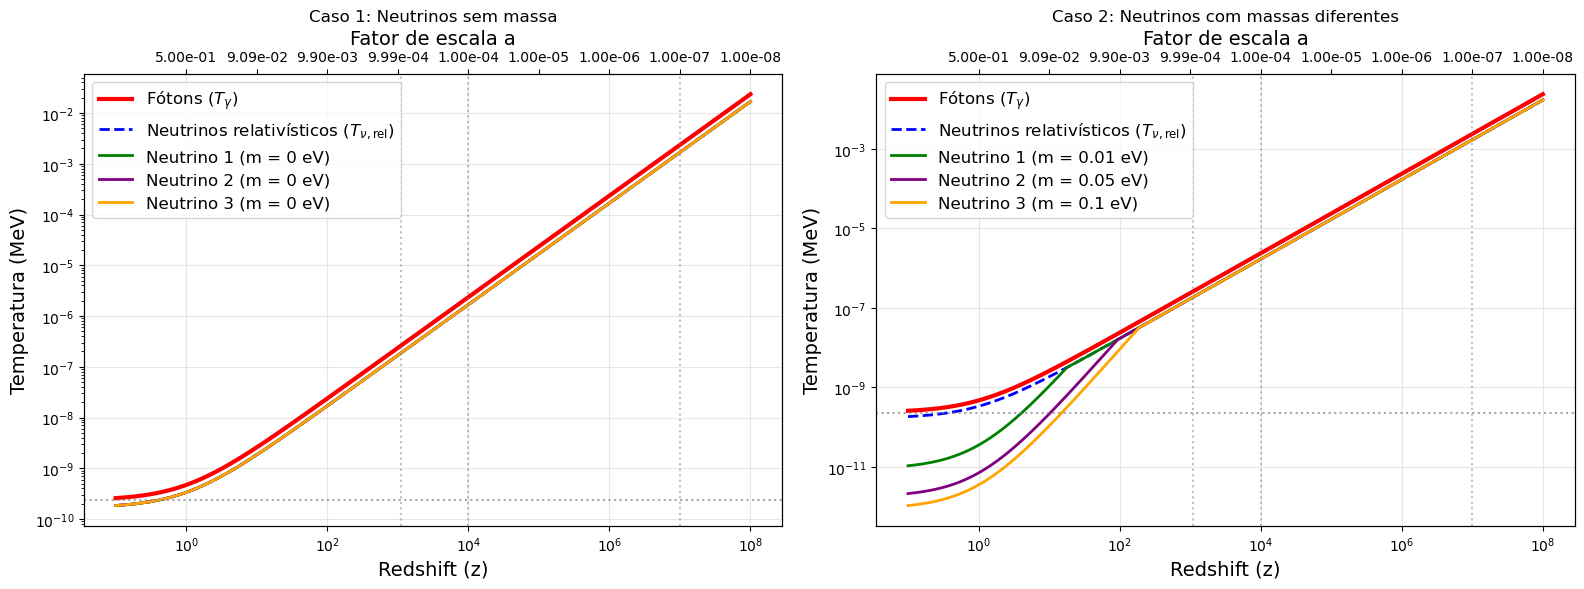

In [ ]:
# | label: neutrinos

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import astropy.units as u

def z_to_a(z):
    """Converte redshift para fator de escala"""
    return 1 / (1 + z)

def a_to_z(a):
    """Converte fator de escala para redshift"""
    return 1 / a - 1

class CosmicThermalHistory:
    """
    Classe para calcular a evolução térmica do universo
    incluindo fótons e neutrinos com diferentes massas
    """

    def __init__(self, neutrino_masses=[0.0, 0.0, 0.0], N_eff=3.046):
        self.neutrino_masses = np.array(neutrino_masses)  # em eV
        self.N_eff = N_eff
        self.N_species = len(neutrino_masses)

        # Constantes físicas
        self.kB = 8.617333262145e-5  # eV/K
        self.T_cmb0 = 2.7255  # K, temperatura atual do CMB
        self.T_nu0 = (4 / 11) ** (1 / 3) * self.T_cmb0  # K, temperatura atual dos neutrinos

        # Redshifts para calcular
        self.z_values = np.logspace(-1, 8, 1000)  # z de 0.1 a 10^8

    def T_gamma(self, z):
        return self.T_cmb0 * (1 + z)

    def T_nu_relativistic(self, z):
        return self.T_nu0 * (1 + z)

    def neutrino_momentum(self, z, mass_eV):
        T_nu = self.T_nu_relativistic(z)
        return 3.15 * self.kB * T_nu  # eV

    def is_relativistic(self, z, mass_eV):
        p = self.neutrino_momentum(z, mass_eV)
        return p > mass_eV

    def T_nu_massive(self, z, mass_eV):
        T_nu_rel = self.T_nu_relativistic(z)

        if mass_eV == 0:
            return T_nu_rel

        p = self.neutrino_momentum(z, mass_eV)

        if p > mass_eV:
            return T_nu_rel
        else:
            T_trans = mass_eV / (3.15 * self.kB)
            z_trans = T_trans / self.T_nu0 - 1

            if z < z_trans:
                a_trans = 1 / (1 + z_trans)
                a = 1 / (1 + z)
                return T_trans * (a_trans / a) ** 2
            else:
                return T_nu_rel

    def calculate_temperatures(self):
        results = {
            "z": self.z_values,
            "T_gamma": (self.T_gamma(self.z_values)*u.K).to(u.MeV, equivalencies=u.temperature_energy()),
            "T_nu_rel": (self.T_nu_relativistic(self.z_values)*u.K).to(u.MeV, equivalencies=u.temperature_energy()),
        }

        for i, mass in enumerate(self.neutrino_masses):
            T_nu = [self.T_nu_massive(z, mass) for z in self.z_values]
            results[f"T_nu_{i + 1}"] = (np.array(T_nu)*u.K).to(u.MeV, equivalencies=u.temperature_energy())

        return results

    def plot_temperatures(self, results, ax=None):
        if ax is None:
            fig, ax = plt.subplots(figsize=(12, 8))

        ax.loglog(results["z"], results["T_gamma"], label=r"Fótons ($T_\gamma$)", linewidth=3, color="red")
        ax.loglog(results["z"], results["T_nu_rel"], "--", label=r"Neutrinos relativísticos ($T_{\nu,\mathrm{rel}}$)", linewidth=2, color="blue")

        colors = ["green", "purple", "orange"]
        for i, mass in enumerate(self.neutrino_masses):
            if mass > 0:
                label = f"Neutrino {i + 1} (m = {mass} eV)"
            else:
                label = f"Neutrino {i + 1} (m = 0 eV)"
            ax.loglog(results["z"], results[f"T_nu_{i + 1}"], label=label, linewidth=2, color=colors[i])

        ax.set_xlabel("Redshift (z)", fontsize=14)
        ax.set_ylabel("Temperatura (MeV)", fontsize=14)
        ax.set_title("Evolução Térmica do Universo: Fótons e Neutrinos", fontsize=16)
        ax.legend(fontsize=12)
        ax.grid(True, alpha=0.3)
        #ax.set_ylim(1, 1e-2)
        #ax.set_xlim(1, a_to_z(1e-14))

        ax.axhline(y=(2.7*u.K).to(u.MeV, equivalencies=u.temperature_energy()).value, color="gray", linestyle=":", alpha=0.7, label="T atual CMB")

        important_z = [0, 1100, 1e4, 1e7]
        for z_val in important_z:
            ax.axvline(x=z_val, color="gray", linestyle=":", alpha=0.5)

        # Eixo x secundário com fator de escala a
        ax2 = ax.twiny()
        ax2.set_xscale('log')
        ax2.set_xlim(ax.get_xlim())
        z_ticks = np.array([1, 10, 100, 1000, 10000, 1e5, 1e6, 1e7, 1e8])
        a_ticks = z_to_a(z_ticks)
        ax2.set_xticks(z_ticks)
        ax2.set_xticklabels([f"{a:.2e}" for a in a_ticks])
        ax2.set_xlabel("Fator de escala a", fontsize=14)
        return ax

    def plot_temperature_ratio(self, results):
        fig, ax = plt.subplots(figsize=(12, 6))

        ratio_rel = results["T_nu_rel"] / results["T_gamma"]
        ax.loglog(results["z"], ratio_rel, "--", label="Neutrinos relativísticos", linewidth=2, color="blue")

        colors = ["green", "purple", "orange"]
        for i, mass in enumerate(self.neutrino_masses):
            ratio = results[f"T_nu_{i + 1}"] / results["T_gamma"]
            if mass > 0:
                label = f"Neutrino {i + 1} (m = {mass} eV)"
            else:
                label = f"Neutrino {i + 1} (m = 0 eV)"
            ax.loglog(results["z"], ratio, label=label, linewidth=2, color=colors[i])

        ax.axhline(y=(4 / 11) ** (1 / 3), color="red", linestyle="--", label=r"$(4/11)^{1/3}$ (teórico)", alpha=0.7)

        ax.set_xlabel("Redshift (z)", fontsize=14)
        ax.set_ylabel(r"$T_\nu / T_\gamma$", fontsize=14)
        ax.set_title("Razão entre Temperaturas de Neutrinos e Fótons", fontsize=16)
        ax.legend(fontsize=12)
        ax.grid(True, alpha=0.3)
        #ax.set_ylim(1e-2, 1.1)

        # Eixo x secundário com fator de escala a
        ax2 = ax.twiny()
        ax2.set_xscale('log')
        ax2.set_xlim(ax.get_xlim())
        z_ticks = np.array([0.1, 1, 10, 100, 1000, 10000, 1e5, 1e6, 1e7, 1e8])
        a_ticks = z_to_a(z_ticks)
        ax2.set_xticks(z_ticks)
        ax2.set_xticklabels([f"{a:.2e}" for a in a_ticks])
        ax2.set_xlabel("Fator de escala a", fontsize=14)

        plt.tight_layout()
        plt.show()

# Exemplo de uso
#if __name__ == "__main__":
# Caso 1: Todos os neutrinos sem massa (3 famílias)
#print("Caso 1: Neutrinos sem massa (3 famílias)")
cosmology1 = CosmicThermalHistory(neutrino_masses=[0.0, 0.0, 0.0], N_eff=3.046)
results1 = cosmology1.calculate_temperatures()
#plot1 = cosmology1.plot_temperatures(results1)
#cosmology1.plot_temperature_ratio(results1)

# Caso 2: Neutrinos com massas diferentes
#print("\nCaso 2: Neutrinos com massas diferentes")
cosmology2 = CosmicThermalHistory(neutrino_masses=[0.01, 0.05, 0.1], N_eff=3.046)
results2 = cosmology2.calculate_temperatures()
#plot2 = cosmology2.plot_temperatures(results2)
#cosmology2.plot_temperature_ratio(results2)

# Caso 3: Efeito do número de espécies
##print("\nCaso 3: Comparação com diferentes N_eff")
fig, ax = plt.subplots(ncols=2, figsize=(16, 6))

ax[0] = cosmology1.plot_temperatures(results1, ax=ax[0])
ax[0].set_title("Caso 1: Neutrinos sem massa")

ax[1] = cosmology2.plot_temperatures(results2, ax=ax[1])
ax[1].set_title("Caso 2: Neutrinos com massas diferentes")

# Caso 3: Efeito do número de espécies
# ax[2].set_title("Caso 3: Efeito do número de espécies")

# # Usa as variáveis já presentes: N_eff, rho_gamma, rho_nu, z_values
# ax[2].loglog(
#     z_values,
#     rho_nu / rho_gamma,
#     label=rf"$\rho_\nu/\rho_\gamma$, $N_{{\mathrm{{eff}}}}$={N_eff}$",
# )

# ax[2].set_xlabel("Redshift (z)", fontsize=14)
# ax[2].set_ylabel(r"$\rho_\nu / \rho_\gamma$", fontsize=14)
# ax[2].set_title("Efeito do Número Efetivo de Espécies de Neutrinos", fontsize=16)
# ax[2].legend(fontsize=12)
# ax[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


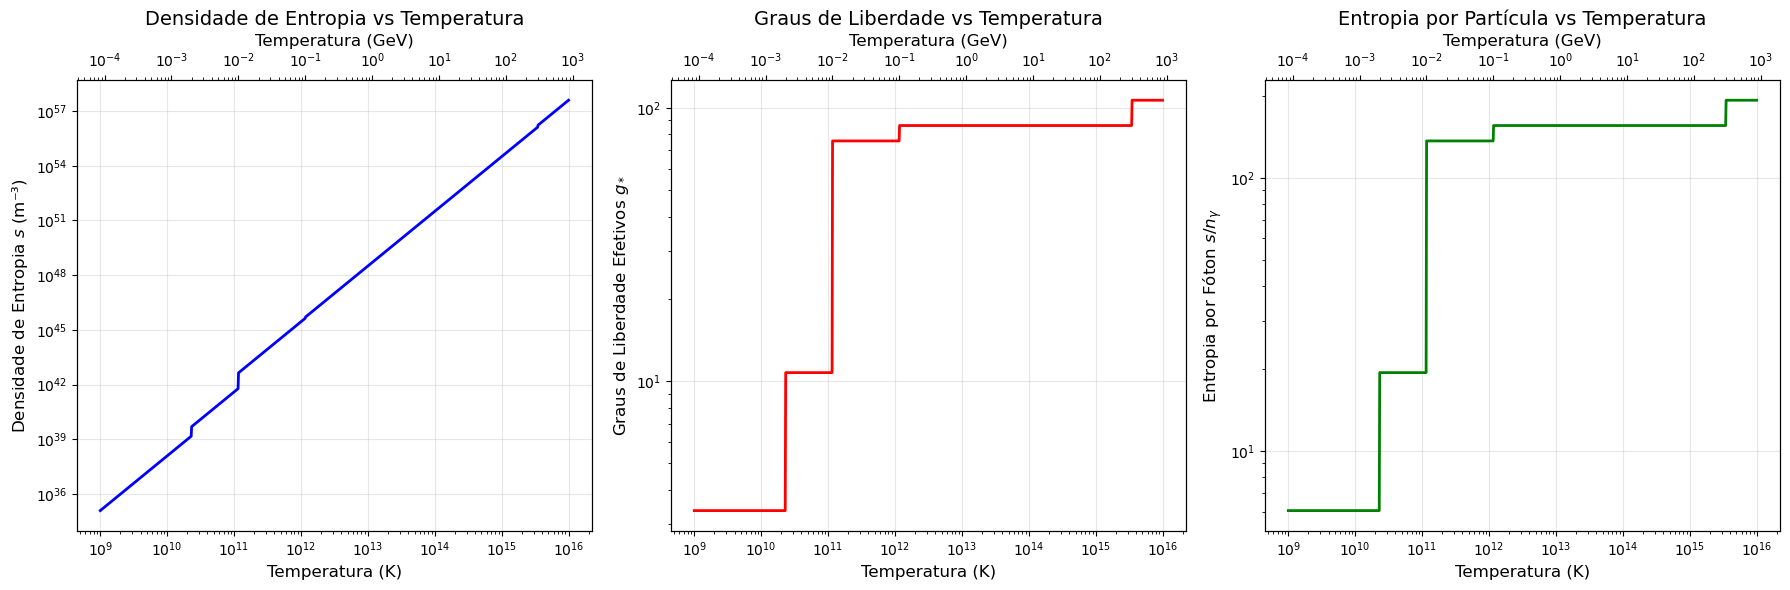

In [ ]:
# | label: entropia

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import physical_constants, Boltzmann


class EntropyDensity:
    def __init__(self):
        # Constantes fundamentais
        self.hbar = physical_constants["Planck constant over 2 pi"][0]  # J·s
        self.c = physical_constants["speed of light in vacuum"][0]  # m/s
        self.kB = Boltzmann  # J/K
        self.eV_to_J = physical_constants["electron volt-joule relationship"][0]

        # Fator de conversão para unidades naturais
        self.conversion_factor = (self.kB**3) / (self.hbar**3 * self.c**3)

    def entropy_density(self, T, g_star):
        """
        Calcula a densidade de entropia para uma dada temperatura e g_star

        Parâmetros:
        T: temperatura em Kelvin
        g_star: graus de liberdade efetivos

        Retorna:
        s: densidade de entropia em m⁻³
        """
        T_SI = T  # Temperatura já está em Kelvin

        # Fórmula: s = (2π²/45) g_* k_B³ T³ / (ħ³c³)
        s = (
            (2 * np.pi**2 / 45)
            * g_star
            * (self.kB * T_SI) ** 3
            / (self.hbar**3 * self.c**3)
        )

        return s

    def g_star_standard_model(self, T):
        """
        Calcula os graus de liberdade efetivos para o Modelo Padrão
        como função da temperatura (em GeV)

        Baseado em dados de:
        - Planck Collaboration (2018)
        - Particle Data Group
        """
        T_GeV = T * self.kB / (1e9 * self.eV_to_J)  # Converter para GeV

        # Aproximação para o Modelo Padrão
        if T_GeV > 300:  # Acima da escala eletrofraca
            g_star = 106.75
        elif T_GeV > 0.1:  # Entre QCD e eletrofraca
            g_star = 86.25
        elif T_GeV > 0.01:  # Após aniquilação múon
            g_star = 75.75
        elif T_GeV > 2e-3:  # Após aniquilação elétron-pósitron
            g_star = 10.75
        else:  # Após aniquilação e⁻e⁺
            g_star = 3.36  # Apenas fótons e neutrinos

        return g_star

    def entropy_density_evolution(self, T_values):
        """
        Calcula a evolução da densidade de entropia com a temperatura
        """
        s_values = []
        g_star_values = []

        for T in T_values:
            g_star = self.g_star_standard_model(T)
            s = self.entropy_density(T, g_star)
            s_values.append(s)
            g_star_values.append(g_star)

        return np.array(s_values), np.array(g_star_values)

    def plot_entropy_evolution(self):
        """
        Plota a evolução da densidade de entropia com a temperatura
        """
        # Faixa de temperaturas de interesse (de 1e9 K a 1e16 K)
        T_values = np.logspace(9, 16, 1000)  # 10^9 a 10^16 K

        s_values, g_star_values = self.entropy_density_evolution(T_values)

        # Criar figura com subplots
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

        # Painel 1: Densidade de entropia vs Temperatura
        ax1.loglog(T_values, s_values, "b-", linewidth=2)
        ax1.set_xlabel("Temperatura (K)", fontsize=12)
        ax1.set_ylabel("Densidade de Entropia $s$ (m⁻³)", fontsize=12)
        ax1.set_title("Densidade de Entropia vs Temperatura", fontsize=14)
        ax1.grid(True, alpha=0.3)

        # Adicionar segundio eixo com escala em GeV
        ax1_twin = ax1.twiny()
        T_GeV_values = T_values * self.kB / (1e9 * self.eV_to_J)
        ax1_twin.loglog(T_GeV_values, s_values, "b-", alpha=0)
        ax1_twin.set_xlabel("Temperatura (GeV)", fontsize=12)

        # Painel 2: Graus de liberdade vs Temperatura
        ax2.loglog(T_values, g_star_values, "r-", linewidth=2)
        ax2.set_xlabel("Temperatura (K)", fontsize=12)
        ax2.set_ylabel("Graus de Liberdade Efetivos $g_*$", fontsize=12)
        ax2.set_title("Graus de Liberdade vs Temperatura", fontsize=14)
        ax2.grid(True, alpha=0.3)

        # Adicionar segundio eixo com escala em GeV
        ax2_twin = ax2.twiny()
        ax2_twin.loglog(T_GeV_values, g_star_values, "r-", alpha=0)
        ax2_twin.set_xlabel("Temperatura (GeV)", fontsize=12)

        # Painel 3: Entropia por partícula
        # Para fótons: n_γ = (2ζ(3)/π²) (kBT/ħc)³
        zeta3 = 1.2020569  # Constante Apéry
        n_gamma = (2 * zeta3 / np.pi**2) * (
            self.kB * T_values / (self.hbar * self.c)
        ) ** 3
        entropy_per_particle = s_values / n_gamma

        ax3.loglog(T_values, entropy_per_particle, "g-", linewidth=2)
        ax3.set_xlabel("Temperatura (K)", fontsize=12)
        ax3.set_ylabel("Entropia por Fóton $s/n_γ$", fontsize=12)
        ax3.set_title("Entropia por Partícula vs Temperatura", fontsize=14)
        ax3.grid(True, alpha=0.3)

        # Adicionar segundio eixo com escala em GeV
        ax3_twin = ax3.twiny()
        ax3_twin.loglog(T_GeV_values, entropy_per_particle, "g-", alpha=0)
        ax3_twin.set_xlabel("Temperatura (GeV)", fontsize=12)

        plt.tight_layout()
        plt.show()

        return T_values, s_values, g_star_values


# Exemplo de uso
if __name__ == "__main__":
    # print("Cálculo da Densidade de Entropia no Universo Primordial")
    # print("=" * 55)

    # Inicializar a classe
    entropy_calc = EntropyDensity()

    # Calcular valores atuais
    T_CMB = 2.7255  # K
    g_star_0 = 3.36  # Apenas fótons e neutrinos hoje

    s_0 = entropy_calc.entropy_density(T_CMB, g_star_0)
    n_gamma_0 = (2 * 1.2020569 / np.pi**2) * (
        entropy_calc.kB * T_CMB / (entropy_calc.hbar * entropy_calc.c)
    ) ** 3
    s_n_ratio_0 = s_0 / n_gamma_0

    # print(f"\nValores atuais (T = {T_CMB} K):")
    # print(f"Densidade de entropia: s = {s_0:.3e} m⁻³")
    # print(f"Densidade de fótons: n_γ = {n_gamma_0:.3e} m⁻³")
    # print(f"Razão entropia/fóton: s/n_γ = {s_n_ratio_0:.3f}")

    # Calcular em diferentes épocas cósmicas
    cosmic_epochs = {
        "Atual": 2.7255,
        "Recombinação": 3000,
        "Nucleossíntese": 1e9,
        "QCD": 2e12,
        "Eletrofraca": 1e15,
    }

    # print(f"\nDensidade de Entropia em Diferentes Épocas:")
    # print(
    #     "Época".ljust(15)
    #     + "T (K)".ljust(15)
    #     + "g_*".ljust(10)
    #     + "s (m⁻³)".ljust(20)
    #     + "s/n_γ"
    # )
    # print("-" * 65)

    for epoch, T in cosmic_epochs.items():
        g_star = entropy_calc.g_star_standard_model(T)
        s = entropy_calc.entropy_density(T, g_star)
        n_gamma = (2 * 1.2020569 / np.pi**2) * (
            entropy_calc.kB * T / (entropy_calc.hbar * entropy_calc.c)
        ) ** 3
        s_n_ratio = s / n_gamma

        # print(
        #     f"{epoch.ljust(15)}{T:.3e}".ljust(15)
        #     + f"{g_star:.2f}".ljust(10)
        #     + f"{s:.3e}".ljust(20)
        #     + f"{s_n_ratio:.2f}"
        # )

    # Plotar a evolução completa
    T_values, s_values, g_star_values = entropy_calc.plot_entropy_evolution()

    # # Demonstrar conservação da entropia
    # print(f"\nDemonstração da Conservação de Entropia:")
  #  print("Durante a expansão adiabática, s ∝ a⁻³ se mantém constante")

    # Escolher duas temperaturas e mostrar que s × a³ é constante
    T1, T2 = 1e15, 1e9  # K
    g1 = entropy_calc.g_star_standard_model(T1)
    g2 = entropy_calc.g_star_standard_model(T2)

    s1 = entropy_calc.entropy_density(T1, g1)
    s2 = entropy_calc.entropy_density(T2, g2)

    # Relação entre fatores de escala
    a2_a1 = T1 / T2  # Para radiação, T ∝ a⁻¹

    # Verificar conservação: s₁ × a₁³ = s₂ × a₂³
    conservation_check = abs(s1 - s2 * (a2_a1) ** 3) / s1

    # print(f"T₁ = {T1:.1e} K, s₁ = {s1:.3e} m⁻³")
    # print(f"T₂ = {T2:.1e} K, s₂ = {s2:.3e} m⁻³")
    # print(f"a₂/a₁ = T₁/T₂ = {a2_a1:.3e}")
    # print(f"s₂ × (a₂/a₁)³ = {s2 * (a2_a1) ** 3:.3e} m⁻³")
    # print(f"Erro relativo: {conservation_check:.2e} (esperado próximo de zero)")


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import physical_constants, Boltzmann

def T_to_a(T, T0=2.7255):
    """Converte temperatura para fator de escala a, assumindo T ∝ a⁻¹"""
    return T0 / T

class EntropyDensity:
    def __init__(self):
        # ...código permanece igual...

    # ...métodos de cálculo permanecem iguais...

    def plot_entropy_evolution(self):
        T_values = np.logspace(9, 16, 1000)  # 10^9 a 10^16 K

        s_values, g_star_values = self.entropy_density_evolution(T_values)

        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

        # Painel 1: Densidade de entropia vs Temperatura
        ax1.loglog(T_values, s_values, 'b-', linewidth=2)
        ax1.set_xlabel('Temperatura (K)', fontsize=12)
        ax1.set_ylabel('Densidade de Entropia $s$ (m⁻³)', fontsize=12)
        ax1.set_title('Densidade de Entropia vs Temperatura', fontsize=14)
        ax1.grid(True, alpha=0.3)

        # Eixo x secundário com fator de escala a
        ax1_twin = ax1.twiny()
        ax1_twin.set_xscale('log')
        ax1_twin.set_xlim(ax1.get_xlim())
        T_ticks = np.logspace(9, 16, 8)
        a_ticks = T_to_a(T_ticks)
        ax1_twin.set_xticks(T_ticks)
        ax1_twin.set_xticklabels([f"{a:.2e}" for a in a_ticks])
        ax1_twin.set_xlabel('Fator de escala a', fontsize=12)

        # Painel 2: Graus de liberdade vs Temperatura
        ax2.loglog(T_values, g_star_values, 'r-', linewidth=2)
        ax2.set_xlabel('Temperatura (K)', fontsize=12)
        ax2.set_ylabel('Graus de Liberdade Efetivos $g_*$', fontsize=12)
        ax2.set_title('Graus de Liberdade vs Temperatura', fontsize=14)
        ax2.grid(True, alpha=0.3)

        ax2_twin = ax2.twiny()
        ax2_twin.set_xscale('log')
        ax2_twin.set_xlim(ax2.get_xlim())
        ax2_twin.set_xticks(T_ticks)
        ax2_twin.set_xticklabels([f"{a:.2e}" for a in a_ticks])
        ax2_twin.set_xlabel('Fator de escala a', fontsize=12)

        # Painel 3: Entropia por partícula
        zeta3 = 1.2020569  # Constante Apéry
        n_gamma = (2 * zeta3 / np.pi**2) * (self.kB * T_values / (self.hbar * self.c))**3
        entropy_per_particle = s_values / n_gamma

        ax3.loglog(T_values, entropy_per_particle, 'g-', linewidth=2)
        ax3.set_xlabel('Temperatura (K)', fontsize=12)
        ax3.set_ylabel('Entropia por Fóton $s/n_γ$', fontsize=12)
        ax3.set_title('Entropia por Partícula vs Temperatura', fontsize=14)
        ax3.grid(True, alpha=0.3)

        ax3_twin = ax3.twiny()
        ax3_twin.set_xscale('log')
        ax3_twin.set_xlim(ax3.get_xlim())
        ax3_twin.set_xticks(T_ticks)
        ax3_twin.set_xticklabels([f"{a:.2e}" for a in a_ticks])
        ax3_twin.set_xlabel('Fator de escala a', fontsize=12)

        plt.tight_layout()
        plt.show()

        return T_values, s_values, g_star_values

# ...restante do código permanece igual...

IndentationError: expected an indented block after function definition on line 10 (3211870732.py, line 15)

Demonstração da Relação Termodinâmica: s = (ρ + P)/T

Verificação da Relação para Diferentes Temperaturas:
T (K)          s (relação)              s (padrão)               Erro Relativo
--------------------------------------------------------------------------------
1.00e+00       1.008764e-15             7.306451e+07             1.00e+00
1.29e+01       2.173317e-12             1.574127e+11             1.00e+00
1.67e+02       4.682270e-09             3.391354e+14             1.00e+00
2.15e+03       1.008764e-05             7.306451e+17             1.00e+00
2.78e+04       2.173317e-02             1.574127e+21             1.00e+00
3.59e+05       4.682270e+01             3.391354e+24             1.00e+00
4.64e+06       1.008764e+05             7.306451e+27             1.00e+00
5.99e+07       2.173317e+08             1.574127e+31             1.00e+00
7.74e+08       4.682270e+11             3.391354e+34             1.00e+00
1.00e+10       1.008764e+15             7.306451e+37             1.

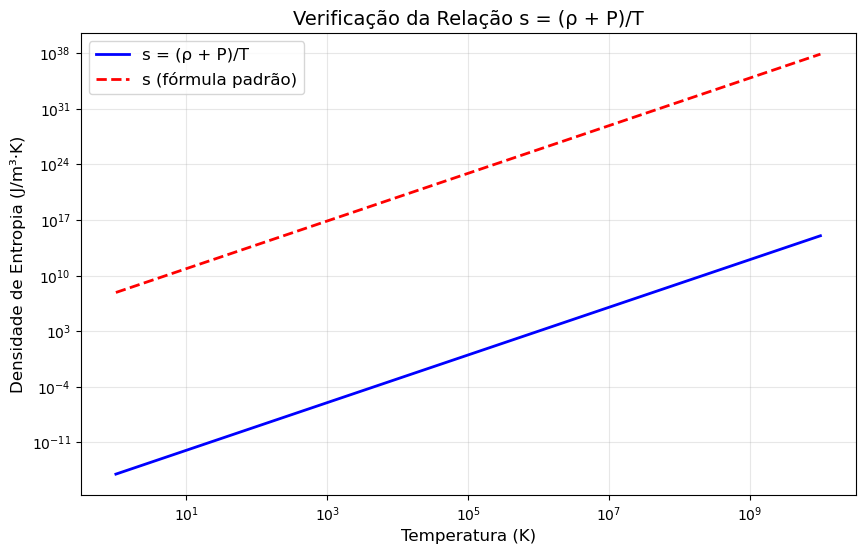

In [ ]:

# import numpy as np
# from scipy.constants import physical_constants, Boltzmann

# class ThermodynamicRelation:
#     def __init__(self):
#         # Constantes físicas
#         self.hbar = physical_constants['Planck constant over 2 pi'][0]  # J·s
#         self.c = physical_constants['speed of light in vacuum'][0]      # m/s
#         self.kB = Boltzmann                                             # J/K
        
#         # Fator de conversão
#         self.conversion = (self.kB**4) / (self.hbar**3 * self.c**3)
    
#     def radiation_energy_density(self, T):
#         """Densidade de energia para radiação de corpo negro"""
#         return (np.pi**2 / 15) * (self.kB * T)**4 / (self.hbar**3 * self.c**3)
    
#     def radiation_pressure(self, T):
#         """Pressão para radiação de corpo negro"""
#         return self.radiation_energy_density(T) / 3
    
#     def entropy_from_relation(self, T):
#         """Calcula entropia usando s = (ρ + P)/T"""
#         rho = self.radiation_energy_density(T)
#         P = self.radiation_pressure(T)
#         return (rho + P) / T
    
#     def entropy_standard(self, T):
#         """Calcula entropia usando a fórmula padrão"""
#         return (4 * np.pi**2 / 45) * (self.kB * T)**3 / (self.hbar**3 * self.c**3)
    
#     def verify_relation(self, T_values):
#         """Verifica a relação s = (ρ + P)/T para um intervalo de temperaturas"""
#         results = []
        
#         for T in T_values:
#             s_from_relation = self.entropy_from_relation(T)
#             s_standard = self.entropy_standard(T)
            
#             relative_error = abs(s_from_relation - s_standard) / s_standard
            
#             results.append({
#                 'T': T,
#                 's_relation': s_from_relation,
#                 's_standard': s_standard,
#                 'error': relative_error
#             })
        
#         return results

# # Demonstração da relação
# def demonstrate_relation():
#     print("Demonstração da Relação Termodinâmica: s = (ρ + P)/T")
#     print("=" * 60)
    
#     thermo = ThermodynamicRelation()
    
#     # Valores de temperatura para testar
#     T_values = np.logspace(0, 10, 10)  # 1 K a 10^10 K
    
#     results = thermo.verify_relation(T_values)
    
#     print("\nVerificação da Relação para Diferentes Temperaturas:")
#     print("T (K)".ljust(15) + "s (relação)".ljust(25) + "s (padrão)".ljust(25) + "Erro Relativo")
#     print("-" * 80)
    
#     for result in results:
#         print(f"{result['T']:.2e}".ljust(15) + 
#               f"{result['s_relation']:.6e}".ljust(25) + 
#               f"{result['s_standard']:.6e}".ljust(25) + 
#               f"{result['error']:.2e}")
    
#     # Demonstração passo a passo para uma temperatura específica
#     T = 2.7255  # Temperatura do CMB
#     print(f"\nDemonstração Detalhada para T = {T} K:")
    
#     rho = thermo.radiation_energy_density(T)
#     P = thermo.radiation_pressure(T)
#     s_relation = thermo.entropy_from_relation(T)
#     s_standard = thermo.entropy_standard(T)
    
#     print(f"Densidade de energia: ρ = {rho:.6e} J/m³")
#     print(f"Pressão: P = {P:.6e} Pa")
#     print(f"ρ + P = {rho + P:.6e} J/m³")
#     print(f"s = (ρ + P)/T = {s_relation:.6e} J/(m³·K)")
#     print(f"s (fórmula padrão) = {s_standard:.6e} J/(m³·K)")
#     print(f"Erro relativo: {abs(s_relation - s_standard)/s_standard:.2e}")

# # Exemplo com gás de férmions
# def fermion_example():
#     print("\n" + "=" * 60)
#     print("Exemplo com Gás de Férmions Relativísticos")
#     print("=" * 60)
    
#     # Para férmions relativísticos (elétrons, quarks, neutrinos)
#     # ρ = (7π²/240) g (kT)⁴/(ħc)³
#     # P = ρ/3
#     # s = (ρ + P)/T = (4ρ)/(3T)
    
#     g = 2  # Graus de liberdade (elétrons)
#     T = 1e9  # 1 GK (temperatura típica da nucleossíntese)
    
#     hbar = physical_constants['Planck constant over 2 pi'][0]
#     c = physical_constants['speed of light in vacuum'][0]
#     kB = Boltzmann
    
#     # Densidade de energia
#     rho_fermion = (7 * np.pi**2 / 240) * g * (kB * T)**4 / (hbar**3 * c**3)
    
#     # Pressão
#     P_fermion = rho_fermion / 3
    
#     # Entropia pela relação
#     s_relation = (rho_fermion + P_fermion) / T
    
#     # Entropia pela fórmula padrão
#     s_standard = (7 * np.pi**2 / 90) * g * (kB * T)**3 / (hbar**3 * c**3)
    
#     print(f"Para férmions relativísticos com g = {g}, T = {T:.1e} K:")
#     print(f"ρ = {rho_fermion:.6e} J/m³")
#     print(f"P = {P_fermion:.6e} Pa")
#     print(f"s = (ρ + P)/T = {s_relation:.6e} J/(m³·K)")
#     print(f"s (fórmula padrão) = {s_standard:.6e} J/(m³·K)")
#     print(f"Erro relativo: {abs(s_relation - s_standard)/s_standard:.2e}")

# if __name__ == "__main__":
#     demonstrate_relation()
#     fermion_example()
    
#     # Demonstração gráfica
#     import matplotlib.pyplot as plt
    
#     thermo = ThermodynamicRelation()
#     T_range = np.logspace(0, 10, 100)
    
#     s_rel = [thermo.entropy_from_relation(T) for T in T_range]
#     s_std = [thermo.entropy_standard(T) for T in T_range]
    
#     plt.figure(figsize=(10, 6))
#     plt.loglog(T_range, s_rel, 'b-', label='s = (ρ + P)/T', linewidth=2)
#     plt.loglog(T_range, s_std, 'r--', label='s (fórmula padrão)', linewidth=2)
#     plt.xlabel('Temperatura (K)', fontsize=12)
#     plt.ylabel('Densidade de Entropia (J/m³·K)', fontsize=12)
#     plt.title('Verificação da Relação s = (ρ + P)/T', fontsize=14)
#     plt.legend(fontsize=12)
#     plt.grid(True, alpha=0.3)
#     plt.show()

